# Determining the Age of Customers from Photos (Computer Vision)

## Project Description

The supermarket chain "Khleb-Sol" introduces a computer vision system that processes photos of customers at the checkout area. Photo capture helps to determine the customers' age in order to:
- analyze purchases and offer products that may interest customers of a given age group;
- control the cashiers' conscientiousness when they sell alcohol.

**Goal:** Build a model that determines the approximate age of a person from a photo. A dataset of photos of people with their ages is available. The quality requirement is a mean absolute error (MAE) of no more than 8 years.

**Plan:**
1. Exploratory data analysis
2. Model training (ResNet50)
3. Analysis of the trained model

> The notebook cannot be run without the photo dataset and a GPU, so the training code is shown in a text block together with its output.

## 1. Exploratory Data Analysis

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [ ]:
labels = pd.read_csv('faces/labels.csv')
train_datagen = ImageDataGenerator(rescale=1./255)
train_gen_flow = train_datagen.flow_from_dataframe(
        dataframe=labels,
        directory='faces/final_files/',
        x_col='file_name',
        y_col='real_age',
        target_size=(224, 224),
        batch_size=32,
        class_mode='raw',
        seed=12345)

Found 7591 validated image filenames.


In [ ]:
labels.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7591 entries, 0 to 7590
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   file_name  7591 non-null   object
 1   real_age   7591 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 118.7+ KB


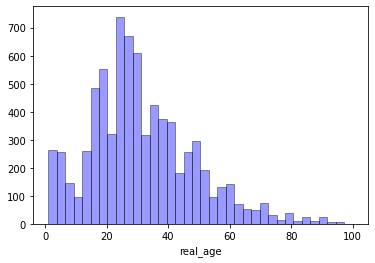

In [ ]:
sns.distplot(labels['real_age'], hist=True, kde=False, 
             bins=int(180/5), color = 'blue',
             hist_kws={'edgecolor':'black'});

Look at the distribution of ages in the sample. There are few outliers and the distribution is close to normal, but it is slightly right-skewed: people aged 18-40 make up most of the sample. There is also a peak in the children's age up to 10 years and a peak in the age group 45-55.

In [ ]:
features_train, target_train = next(train_gen_flow)
fig = plt.figure(figsize=(10,10))
for i in range(10):
    fig.add_subplot(4, 4, i+1)
    plt.imshow(features_train[i])
    plt.xticks([])
    plt.yticks([])
    plt.tight_layout()
    plt.title('Age ={}'.format(target_train[i]), loc='center')

Print 10 sample photos from the dataset. Visually, the age labels look correct. The photos differ in crop, lighting and color (some are black and white or slightly rotated with black borders), so the only preprocessing used is rescaling of the pixel values to the range [0, 1].

*(The output of this cell, a grid of 10 labeled sample faces, is not included in this repository to avoid publishing photos of people.)*

## 2. Model Training

The training code was run in a separate GPU environment, so it is shown as a text block with its output.

The model is a ResNet50 backbone pretrained on ImageNet, followed by global average pooling and one output neuron that predicts the age. It is trained for 5 epochs with the Adam optimizer (learning rate 0.0001) and the MSE loss; the MAE is the quality metric. 75% of the images are used for training and 25% for validation.

```python
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Flatten, Dense, GlobalAveragePooling2D
import numpy as np
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet import ResNet50
import pandas as pd


def load_train(path):
    # training part of the data: 75% of the images
    datagen = ImageDataGenerator(validation_split=0.25, rescale=1./255)
    labels = pd.read_csv(path + 'labels.csv')
    train_datagen_flow = datagen.flow_from_dataframe(dataframe=labels,
                                                     directory=path + 'final_files/', 
                                                     x_col='file_name',
                                                     y_col='real_age',
                                                     target_size=(224, 224), 
                                                     batch_size=16, 
                                                     class_mode='raw', 
                                                     subset='training',
                                                     seed=12345)
    return train_datagen_flow

def load_test(path):
    # validation part of the data: the remaining 25% of the images
    datagen = ImageDataGenerator(validation_split=0.25, rescale=1./255)
    labels = pd.read_csv(path + 'labels.csv')
    test_datagen_flow = datagen.flow_from_dataframe(dataframe=labels,
                                                     directory=path + 'final_files/', 
                                                     x_col='file_name',
                                                     y_col='real_age', 
                                                     target_size=(224, 224), 
                                                     batch_size=16, 
                                                     class_mode='raw', 
                                                     subset='validation',
                                                     seed=12345)
    return test_datagen_flow


def create_model(input_shape):
    # ResNet50 pretrained on ImageNet as the backbone, without its classification head
    backbone = ResNet50(input_shape=input_shape, weights='imagenet', include_top=False)
 
    model = Sequential()
    model.add(backbone)
    model.add(GlobalAveragePooling2D())
    # one output neuron: the predicted age (a regression task)
    model.add(Dense(units=1, activation='relu')) 
 
    # MSE loss for training, MAE as the quality metric
    optimizer = Adam(lr=0.0001) 
    model.compile(optimizer=optimizer, loss='mean_squared_error', metrics=['mae'])
    return model


def train_model(model, train_data, test_data, batch_size=None, epochs=5,
               steps_per_epoch=None, validation_steps=None):
    
    # by default one epoch passes over the whole training set
    if steps_per_epoch is None:
        steps_per_epoch = len(train_data)
    if validation_steps is None:   
        validation_steps=len(test_data)
    
    model.fit(train_data, 
              validation_data=test_data,
              batch_size=batch_size, epochs=epochs,
              steps_per_epoch=steps_per_epoch,
              validation_steps=validation_steps,
              verbose=2, shuffle=True)

    return model
```

```
Found 5694 validated image filenames.
Found 1897 validated image filenames.
<class 'tensorflow.python.keras.engine.sequential.Sequential'>
Train for 356 steps, validate for 119 steps
Epoch 1/5
356/356 - 54s - loss: 203.0665 - mae: 10.2637 - val_loss: 511.8529 - val_mae: 17.3415
Epoch 2/5
356/356 - 43s - loss: 64.5924 - mae: 6.1034 - val_loss: 163.8184 - val_mae: 10.0429
Epoch 3/5
356/356 - 49s - loss: 34.9699 - mae: 4.5978 - val_loss: 124.7827 - val_mae: 8.6701
Epoch 4/5
356/356 - 56s - loss: 25.9660 - mae: 3.9325 - val_loss: 77.7641 - val_mae: 6.7367
Epoch 5/5
356/356 - 55s - loss: 19.2278 - mae: 3.3695 - val_loss: 74.2793 - val_mae: 6.5204
119/119 - 11s - loss: 74.2793 - mae: 6.5204
Test MAE: 6.5204
Test MAE: 6.2263
```

## 3. Analysis of the Trained Model

The model was trained with Keras and checked against the required MAE threshold of 8 years. The final MAE on the validation set is 6.23 years (the last line of the training log above), which is below the threshold.

There were two business tasks:
1. Analyze purchases and offer products for the relevant age group. The model solves this task well.
2. Control the cashiers' conscientiousness when they sell alcohol. The error of about 6 years is too large for accurate age predictions, so this task cannot be solved with this model.

The training metrics also show strong overfitting (the training MAE is 3.37 against 6.52 on the validation set at the last epoch), which is a common problem of neural networks.